# 03 · Risk segmentation

**Question:** can the portfolio be split into a few risk tiers that need different actions?

K-Means groups customers on five behaviour features: utilisation, months late, worst
arrears, payment ratio and credit limit (log). The clusters are then ranked by their
observed default rate and labelled Tier 1 (lowest risk) to Tier 4 (highest).
Each customer also carries the out-of-fold model PD from notebook 02.

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
SEED = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data" / "clean" / "credit_card_clients_clean.csv")
pd_scores = pd.read_csv(ROOT / "data" / "output" / "pd_scores.csv")
df = df.merge(pd_scores, on="ID", validate="one_to_one")

seg_features = pd.DataFrame({
    "utilisation": df["UTILISATION"].clip(upper=1.5),
    "months_late": df["MONTHS_LATE_6M"],
    "max_delinquency": df["MAX_DELINQUENCY_6M"].clip(upper=4),
    "payment_ratio": df["PAYMENT_RATIO_6M"],
    "log_limit": np.log(df["LIMIT_BAL"]),
})
Z = StandardScaler().fit_transform(seg_features)

## Choosing the number of clusters

In [2]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(Z), 5000, replace=False)
scores = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    scores.append({"k": k, "inertia": km.inertia_,
                   "silhouette": silhouette_score(Z[idx], km.labels_[idx])})
pd.DataFrame(scores).round(3)

,k,inertia,silhouette
0,2,98453.475,0.386
1,3,62358.312,0.405
2,4,52216.268,0.358
3,5,44061.789,0.359
4,6,38767.573,0.370
5,7,34125.962,0.355


Four clusters is chosen for business use: it gives four actionable tiers and keeps a
reasonable silhouette score. The scores above show the trade-off.

In [3]:
km = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(Z)
df["cluster"] = km.labels_
order = df.groupby("cluster")["DEFAULT_NEXT_MONTH"].mean().sort_values().index
names = ["Tier 1 - Low", "Tier 2 - Moderate", "Tier 3 - Elevated", "Tier 4 - High"]
df["RISK_TIER"] = df["cluster"].map(dict(zip(order, names)))

profile = (df.groupby("RISK_TIER")
             .agg(customers=("ID", "size"),
                  default_rate=("DEFAULT_NEXT_MONTH", "mean"),
                  avg_model_pd=("PD_SCORE", "mean"),
                  avg_utilisation=("UTILISATION", "mean"),
                  avg_months_late=("MONTHS_LATE_6M", "mean"),
                  avg_payment_ratio=("PAYMENT_RATIO_6M", "mean"),
                  avg_limit_ntd=("LIMIT_BAL", "mean")))
profile.insert(1, "portfolio_share", profile["customers"] / len(df))
profile.round(3)

,customers,portfolio_share,default_rate,avg_model_pd,avg_utilisation,avg_months_late,avg_payment_ratio,avg_limit_ntd
RISK_TIER,,,,,,,,
Tier 1 - Low,6684,0.223,0.081,0.087,0.292,0.059,0.157,252173.848
Tier 2 - Moderate,7066,0.236,0.140,0.138,0.851,0.001,0.089,88159.875
Tier 3 - Elevated,9049,0.302,0.171,0.169,0.026,0.319,0.886,225569.676
Tier 4 - High,7201,0.240,0.495,0.492,0.627,3.019,0.095,93720.594


## Tier reporting in SQL
The tiers are written back to SQLite and reported with `sql/03_segmentation_queries.sql`.

In [4]:
con = sqlite3.connect(ROOT / "data" / "portfolio.db")
con.execute("DELETE FROM risk_tiers")
df[["ID", "RISK_TIER", "PD_SCORE"]].to_sql("risk_tiers", con, if_exists="append", index=False)
con.commit()
df[["ID", "RISK_TIER", "PD_SCORE"]].to_csv(ROOT / "data" / "output" / "risk_tiers.csv", index=False)

text = (ROOT / "sql" / "03_segmentation_queries.sql").read_text()
seg = {}
for block in re.split(r"^-- name: ", text, flags=re.M)[1:]:
    name, sql = block.split("\n", 1)
    seg[name.strip()] = pd.read_sql(sql, con)
seg["tier_summary"]

,risk_tier,customers,portfolio_share_pct,default_rate_pct,avg_model_pd_pct,avg_utilisation_pct
0,Tier 1 - Low,6684,22.3,8.1,8.7,29.2
1,Tier 2 - Moderate,7066,23.6,14.0,13.8,85.1
2,Tier 3 - Elevated,9049,30.2,17.1,16.9,2.6
3,Tier 4 - High,7201,24.0,49.5,49.2,62.7


In [5]:
seg["exposure_at_default_by_tier"]

,risk_tier,balance_ntd_m,defaulted_balance_ntd_m,share_of_defaulted_balance_pct
0,Tier 1 - Low,526.8,43.8,13.6
1,Tier 2 - Moderate,563.2,75.5,23.4
2,Tier 3 - Elevated,46.2,3.5,1.1
3,Tier 4 - High,401.2,199.1,61.9


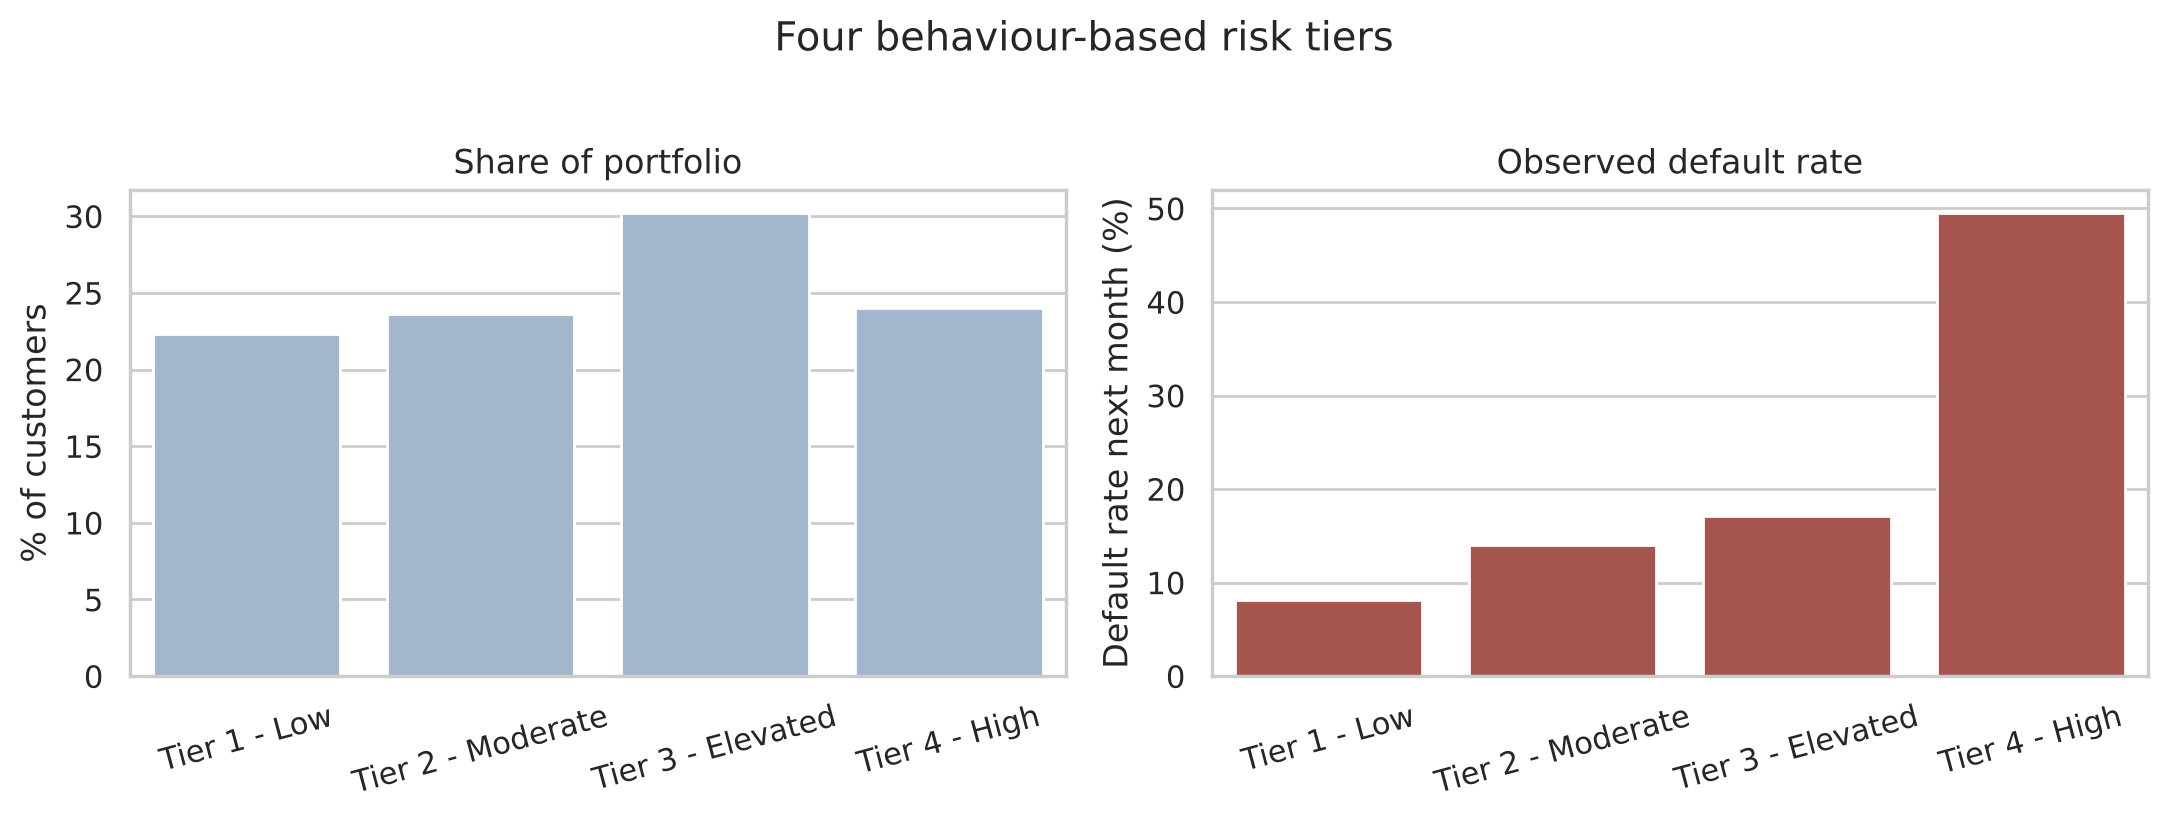

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ts = seg["tier_summary"]
sns.barplot(data=ts, x="risk_tier", y="portfolio_share_pct", color="#9bb7d4", ax=axes[0])
axes[0].set(xlabel="", ylabel="% of customers", title="Share of portfolio")
sns.barplot(data=ts, x="risk_tier", y="default_rate_pct", color="#b5483f", ax=axes[1])
axes[1].set(xlabel="", ylabel="Default rate next month (%)", title="Observed default rate")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Four behaviour-based risk tiers", y=1.02)
plt.tight_layout()
plt.savefig(IMG / "risk_segments.png", dpi=150, bbox_inches="tight")
plt.show()

## Candidate risk appetite metrics
Simple, monitorable thresholds suggested by the data.

In [7]:
high_util = df["UTILISATION"] >= 0.8
late2 = df["PAY_1"] >= 2
appetite = pd.DataFrame({
    "metric": ["Utilisation >= 80%", "2+ months in arrears (Sept)", "Tier 4 share of customers"],
    "share_of_customers_pct": [high_util.mean() * 100, late2.mean() * 100,
                               (df["RISK_TIER"] == names[-1]).mean() * 100],
    "default_rate_pct": [df.loc[high_util, "DEFAULT_NEXT_MONTH"].mean() * 100,
                         df.loc[late2, "DEFAULT_NEXT_MONTH"].mean() * 100,
                         df.loc[df["RISK_TIER"] == names[-1], "DEFAULT_NEXT_MONTH"].mean() * 100],
}).round(1)
appetite.to_csv(ROOT / "data" / "output" / "risk_appetite_metrics.csv", index=False)
profile.round(4).to_csv(ROOT / "data" / "output" / "tier_profile.csv")
appetite

,metric,share_of_customers_pct,default_rate_pct
0,Utilisation >= 80%,26.6,26.7
1,2+ months in arrears (Sept),10.4,69.6
2,Tier 4 share of customers,24.0,49.5
